In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import joblib
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# Membaca dataset
df = pd.read_csv("Life Expectancy Data.csv")
# Melakukan pembersihan sederhana pada nama kolom (menghilangkan spasi ekstra)
df.columns = df.columns.str.strip()

In [3]:
# Menampilkan ringkasan informasi
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [4]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

Jumlah baris : 2938
Jumlah kolom : 22


In [5]:
# Menampilkan statistik deskriptif dari dataset
df.describe(include="all")

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938,2938.000000,2938,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,...,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
unique,193,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Afghanistan,NaN,Developing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,16,NaN,2426,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2007.518720,NaN,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,...,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,NaN,4.613841,NaN,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,...,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,NaN,2000.000000,NaN,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,...,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,NaN,2004.000000,NaN,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,...,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,NaN,2008.000000,NaN,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,...,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,NaN,2012.000000,NaN,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,...,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000


In [6]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = pd.DataFrame({
    'Missing_Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
print("\n--- Missing Values ---")
print(missing_values[missing_values['Missing_Values'] > 0])


--- Missing Values ---
                                 Missing_Values  Percentage (%)
Life expectancy                              10        0.340368
Adult Mortality                              10        0.340368
Alcohol                                     194        6.603131
Hepatitis B                                 553       18.822328
BMI                                          34        1.157250
Polio                                        19        0.646698
Total expenditure                           226        7.692308
Diphtheria                                   19        0.646698
GDP                                         448       15.248468
Population                                  652       22.191967
thinness  1-19 years                         34        1.157250
thinness 5-9 years                           34        1.157250
Income composition of resources             167        5.684139
Schooling                                   163        5.547992


In [7]:
# Menangani Missing Values untuk kolom numerik & kategorika secara aman
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

categorical_cols = df.select_dtypes(include=['str']).columns
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [8]:
# Menangani duplikasi data
print(f"\nJumlah baris duplikat sebelum dihapus: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)


Jumlah baris duplikat sebelum dihapus: 0


In [9]:
# Mengonversi Tipe Data Kategorikal (Encoding) pada kolom 'Status'
le = LabelEncoder()
df['Status'] = le.fit_transform(df['Status'])

# Menghapus kolom 'Country' karena berupa teks unik (nama negara) yang tidak langsung digunakan dalam regresi numerik sederhana
if 'Country' in df.columns:
    df_model = df.drop(columns=['Country'])
else:
    df_model = df.copy()

In [10]:
df_model.head()

,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,2015,1,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,2014,1,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,2013,1,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,2012,1,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,2011,1,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [11]:
# Pengecekan akhir apakah masih ada NaN sebelum scaling
print("\nJumlah Missing Values setelah cleaning:")
print(df_model.isnull().sum().sum())


Jumlah Missing Values setelah cleaning:
0


In [12]:
# Normalisasi / Standarisasi fitur numerik (kecuali target 'Life expectancy')
scaler = StandardScaler()
features_to_scale = [col for col in df_model.columns if col != 'Life expectancy']
df_model[features_to_scale] = scaler.fit_transform(df_model[features_to_scale])

print("\nData Cleaning dan Transformasi selesai. Ukuran dataframe:", df_model.shape)


Data Cleaning dan Transformasi selesai. Ukuran dataframe: (2938, 21)


In [13]:
# Cek apakah kolom 'Life expectancy' benar-and ada
target_col = 'Life expectancy'
if target_col not in df.columns:
    # Cari alternatif jika ada perbedaan spasi kecil
    target_col = [c for c in df.columns if 'life' in c.lower()][0]

print(f"Kolom target yang digunakan: {repr(target_col)}")

Kolom target yang digunakan: 'Life expectancy'


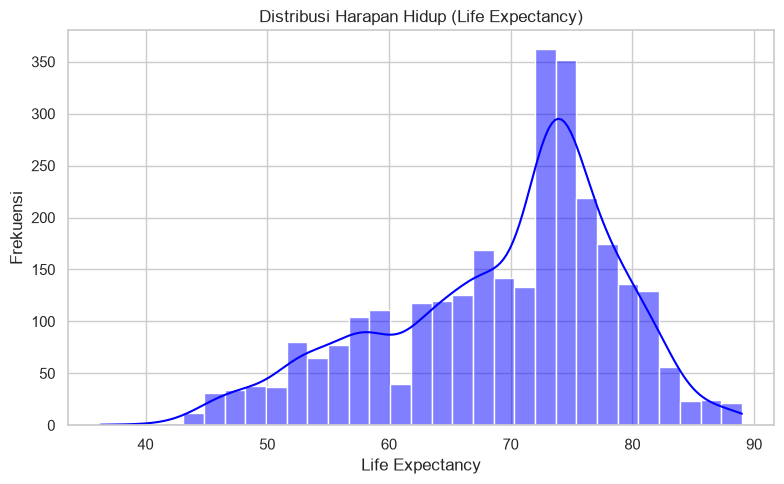

In [14]:
# Mengatur gaya visualisasi
sns.set(style="whitegrid")

# Visualisasi distribusi target utama: 'Life expectancy'
plt.figure(figsize=(8, 5))
sns.histplot(df_model['Life expectancy'], kde=True, color='blue')
plt.title('Distribusi Harapan Hidup (Life Expectancy)')
plt.xlabel('Life Expectancy')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

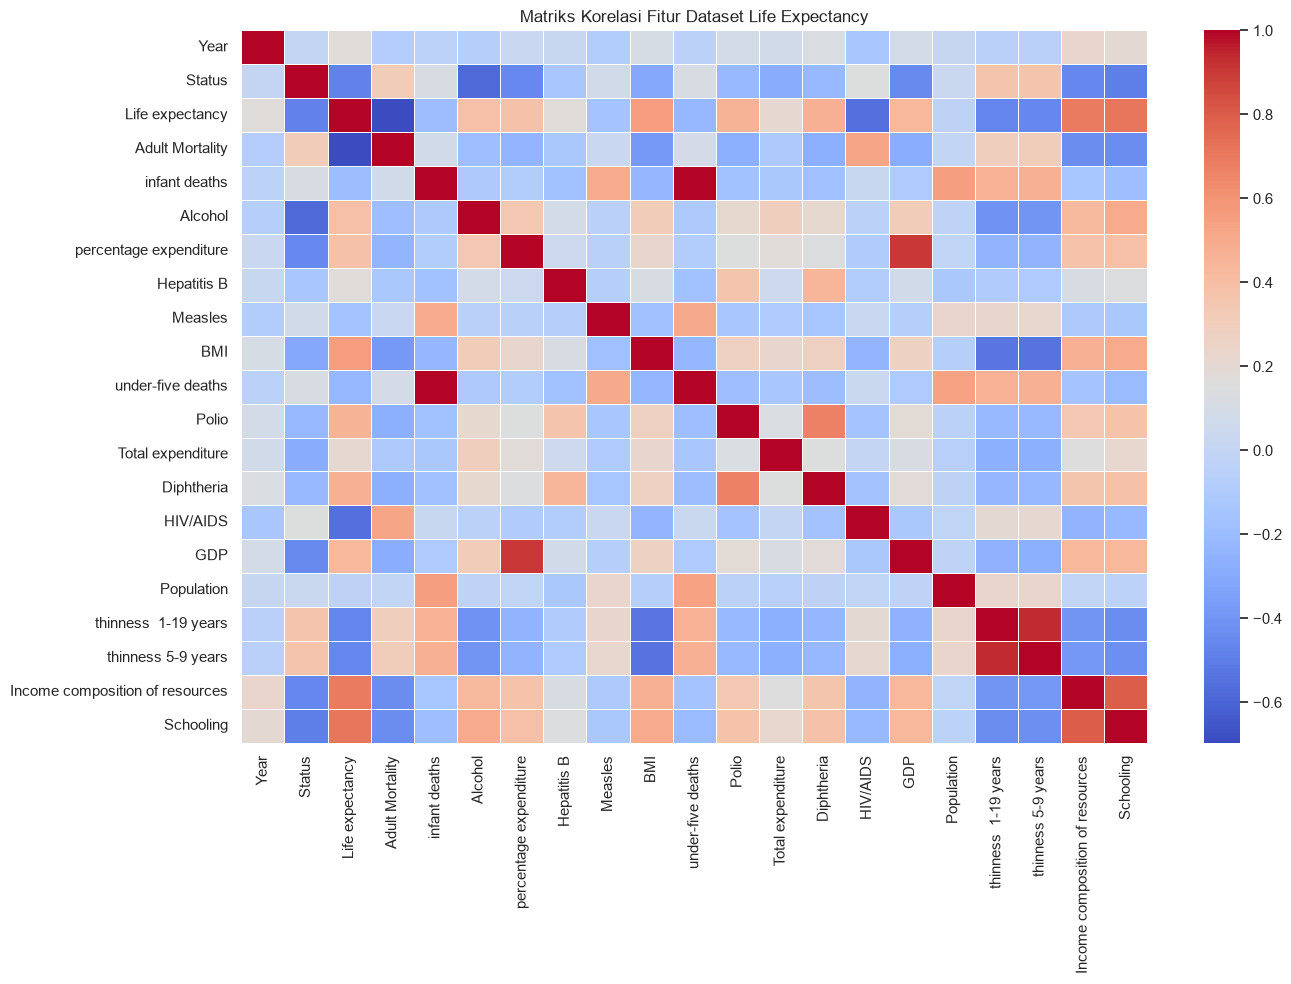

In [15]:
# Visualisasi Matriks Korelasi (Correlation Matrix)
plt.figure(figsize=(14, 10))
correlation_matrix = df_model.corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Matriks Korelasi Fitur Dataset Life Expectancy')
plt.tight_layout()
plt.show()

In [16]:
# Menghitung korelasi spesifik fitur terhadap target 'Life expectancy'
target_corr = correlation_matrix['Life expectancy'].sort_values(ascending=False)
print("--- Korelasi Fitur Terhadap Life Expectancy ---")
print(target_corr)

--- Korelasi Fitur Terhadap Life Expectancy ---
Life expectancy                    1.000000
Schooling                          0.713054
Income composition of resources    0.688662
BMI                                0.556901
Diphtheria                         0.472211
Polio                              0.458399
GDP                                0.430461
Alcohol                            0.388918
percentage expenditure             0.381418
Total expenditure                  0.208844
Year                               0.170819
Hepatitis B                        0.170219
Population                        -0.029014
Measles                           -0.157767
infant deaths                     -0.196769
under-five deaths                 -0.222738
thinness 5-9 years                -0.462473
thinness  1-19 years              -0.468002
Status                            -0.481415
HIV/AIDS                          -0.556703
Adult Mortality                   -0.696390
Name: Life expectancy, dtype

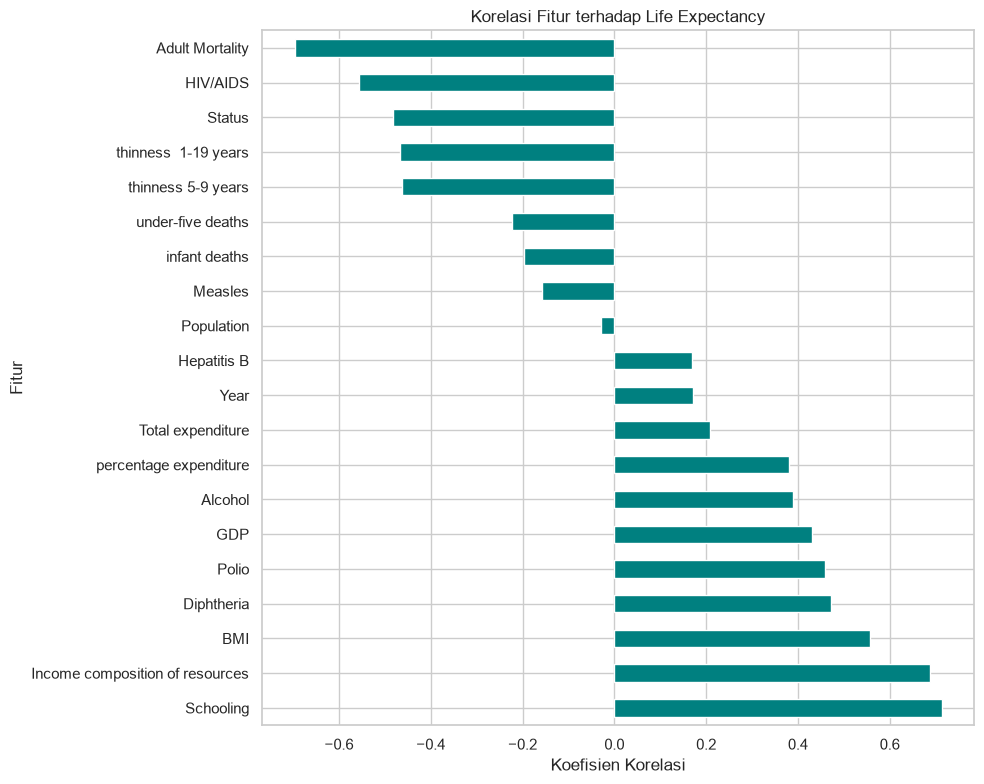

In [17]:
# Bar plot korelasi fitur terhadap target
plt.figure(figsize=(10, 8))
target_corr.drop('Life expectancy').plot(kind='barh', color='teal')
plt.title('Korelasi Fitur terhadap Life Expectancy')
plt.xlabel('Koefisien Korelasi')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

In [18]:
# Memisahkan variabel fitur (X) dan variabel target (y)
X = df_model.drop(columns=['Life expectancy'])
y = df_model['Life expectancy']

# Membagi dataset menjadi training set (80%) dan testing set (20%)
# random_state digunakan agar hasil pembagian konsisten dan dapat direproduksi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Verifikasi ukuran / panjang data setelah splitting
print("Jumlah total data:", len(df_model))
print("Jumlah data latih (X_train):", len(X_train))
print("Jumlah data uji (X_test):", len(X_test))

Jumlah total data: 2938
Jumlah data latih (X_train): 2350
Jumlah data uji (X_test): 588


In [19]:
# Menangani Outliers menggunakan metode Interquartile Range (IQR)
columns_to_check = ['Adult Mortality', 'BMI', 'GDP']

for col in columns_to_check:
    if col in X_train.columns:
        # Hitung Q1 dan Q3 HANYA dari data train untuk menghindari data leakage
        Q1 = X_train[col].quantile(0.25)
        Q3 = X_train[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Lakukan clipping (Winsorization) pada X_train
        X_train[col] = np.where(X_train[col] < lower_bound, lower_bound, X_train[col])
        X_train[col] = np.where(X_train[col] > upper_bound, upper_bound, X_train[col])

        # Terapkan batas yang sama ke X_test agar konsisten
        if col in X_test.columns:
            X_test[col] = np.where(X_test[col] < lower_bound, lower_bound, X_test[col])
            X_test[col] = np.where(X_test[col] > upper_bound, upper_bound, X_test[col])

In [20]:
# Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](20,)","[ 0.02,-0.62,-2.75,..., 0.13, 1.24, 1.94]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['Year','Status','Adult Mortality',...,'thinness 5-9 years', 'Income composition of resources','Schooling']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,69.64
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)


In [21]:
# Model 2: RandomForest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [22]:
# Model 3: Gradient Boosting Regressor
gbr = GradientBoostingRegressor(random_state=184)
gbr.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",184
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

In [23]:
# Evaluasi Model pada Data Testing
results = {'Model': [], 'MAE': [], 'MSE': [], 'RMSE': [], 'R2_Score': []}

models = {
    'Linear Regression': lr,
    'Random Forest Regressor': rf,
    'Gradient Boosting Regressor': gbr
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results['Model'].append(name)
    results['MAE'].append(mae)
    results['MSE'].append(mse)
    results['RMSE'].append(rmse)
    results['R2_Score'].append(r2)

df_results = pd.DataFrame(results)
print("\n--- Tabel Perbandingan Performa Model ---")
print(df_results.to_string(index=False))


--- Tabel Perbandingan Performa Model ---
                      Model      MAE       MSE     RMSE  R2_Score
          Linear Regression 2.856131 15.081114 3.883441  0.825989
    Random Forest Regressor 1.100235  2.829841 1.682213  0.967348
Gradient Boosting Regressor 1.504398  4.295893 2.072654  0.950432


In [24]:
# Memilih model dengan R2 Score tertinggi
best_model_name = df_results.loc[df_results["R2_Score"].idxmax(), "Model"]
best_model = models[best_model_name]

# Menyimpan model menggunakan Joblib (direkomendasikan untuk model scikit-learn berukuran besar)
joblib.dump(best_model, 'best_life_expectancy_model.joblib')
joblib.dump(scaler, 'best_life_expectancy_scaler.joblib')
print(f"\nModel terbaik ({best_model_name}) berhasil disimpan ke file menggunakan Joblib ('best_life_expectancy_model.joblib').")


Model terbaik (Random Forest Regressor) berhasil disimpan ke file menggunakan Joblib ('best_life_expectancy_model.joblib').
